In [1]:
from domino.data.data import *
from scipy import stats
from scipy.stats import gaussian_kde
from domino.models.domino_models import DominoSingleOutput
from domino.utils import tools
from domino.data.domino_data import GenomeDataset
import matplotlib.pyplot as plt
import pytorch_lightning as pl
from domino.data.data import preprocess_data
from domino.utils.tools import seq_from_df
import matplotlib.ticker as mticker


import seaborn as sns
import os

plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'


In [2]:
def get_performance_df(model_dir, DNA_context_bin_width, mode='val'):
    pccs, sccs, mses = [], [], []
    layer_convs = []
    num_filters = []

    for conv_layers in [1, 2, 3, 4, 5, 6, 7]:
        for filter_number in [256]:
            directory = f'DominoSingleOutput_10_{DNA_context_bin_width}_2_1_200_32_False_False_42_0.001_plateau_{conv_layers}_1_512_5_{filter_number}_5_4_64_gelu'
            performance_pth = os.path.join(model_dir, directory, f'{mode}_performance.txt')
            
            if not os.path.exists(os.path.join(model_dir, directory, f'{mode}_performance.txt')):
                pccs.append(None)
                sccs.append(None)
                mses.append(None)
                layer_convs.append(conv_layers)
                continue
            
            with open(performance_pth) as file:
                pcc, scc, mse = [float(num) for num in file.read().split()[:3]]
                pccs.append(pcc)
                sccs.append(scc)
                mses.append(mse)
                layer_convs.append(conv_layers)

    df = pd.DataFrame(
       {
           'pearson': pccs,
           'spearman': sccs,
           'mse': mses,
           'conv_layers': layer_convs
       }
    )
    return df

In [13]:
import numpy as np
from scipy.stats import pearsonr, spearmanr

def correlation_finite(x, y, metric='spearman'):
    """
    Calculates correlations, ignoring non-finite values (NaN, inf) 
    in both arrays.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    
    valid_mask = np.isfinite(x) & np.isfinite(y)
    
    x_valid = x[valid_mask]
    y_valid = y[valid_mask]
    
    if len(x_valid) < 2:
        return np.nan, np.nan
        
    if metric == 'spearman':
        return spearmanr(x_valid, y_valid)[0]

    if metric == 'pearson':
        return pearsonr(x_valid, y_valid)[0]

In [5]:
df_8 = get_performance_df('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13/', 8)
df_16 = get_performance_df('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13/', 16)
df_12 = get_performance_df('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13/', 12)
df_20 = get_performance_df('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13/', 20)

val_df = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu//VAL_df.csv')
rep_spearman = correlation_finite(val_df['demeaned_ins_score_1'], val_df['demeaned_ins_score_2'], 'spearman')
pred_spearman = correlation_finite(val_df['demeaned_ins_score_1'], val_df['pred'], 'spearman')

print(rep_spearman)
print(pred_spearman)

0.83101508645074
0.8215030765883342


In [9]:
df_8 = get_performance_df('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13/', 8)
df_16 = get_performance_df('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13/', 16)
df_12 = get_performance_df('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13/', 12)
df_20 = get_performance_df('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13/', 20)

train_df = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu//TRAIN_df.csv')
rep_spearman = correlation_finite(train_df['demeaned_ins_score_1'], train_df['demeaned_ins_score_2'], 'spearman')
pred_spearman = correlation_finite(train_df['demeaned_ins_score_1'], train_df['pred'], 'spearman')

print(rep_spearman)
print(pred_spearman)

0.8244805863207112
0.8365473846366163


['16', '8', '12', '20']


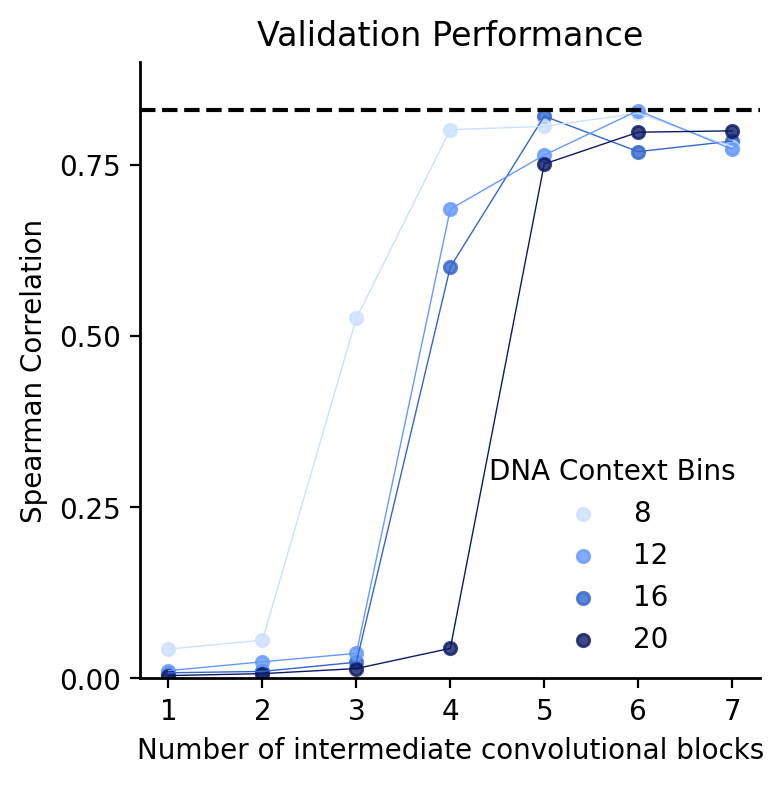

In [6]:
colors = [
    (0.8, 0.88, 1.0, 1.0),  # Light pastel blue
    (0.4, 0.6, 1.0, 1.0),   # Sky blue
    (0.2, 0.4, 0.8, 1.0),   # Medium blue
    (0.05, 0.1, 0.4, 1.0),  # Dark navy blue
]
b1, b2, b3, b4 = colors

fig, ax = plt.subplots(figsize=(4,4))
plt.plot(df_16['conv_layers'], df_16['spearman'], color=b3, linewidth=0.5)
plt.scatter(df_16['conv_layers'], df_16['spearman'], s=20, color=b3, alpha=0.8, label='16')
plt.plot(df_8['conv_layers'], df_8['spearman'], color=b1, linewidth=0.5)
plt.scatter(df_8['conv_layers'], df_8['spearman'], s=20, color=b1, alpha=0.8, label='8')
plt.plot(df_12['conv_layers'], df_12['spearman'], color=b2, linewidth=0.5)
plt.scatter(df_12['conv_layers'], df_12['spearman'], s=20, color=b2, alpha=0.8, label='12')
plt.plot(df_20['conv_layers'], df_20['spearman'], color=b4, linewidth=0.5)
plt.scatter(df_20['conv_layers'], df_20['spearman'], s=20, color=b4, alpha=0.8, label='20')

plt.grid(False)


ax.spines['top'].set_visible(False)     
ax.spines['right'].set_visible(False)   
ax.spines['left'].set_edgecolor('black')  
ax.spines['left'].set_linewidth(1)      
ax.spines['bottom'].set_edgecolor('black')
ax.spines['bottom'].set_linewidth(1)  
ax.yaxis.set_tick_params(left=True)   
ax.xaxis.set_tick_params(bottom=True) 
plt.axhline(y=rep_spearman, linestyle='dashed', color='black')
ax.set_yticks([0, 0.25, 0.5, 0.75])
ax.set_xticks([1, 2, 3, 4, 5, 6, 7])
plt.ylim([0, 0.9])

plt.xlabel('Number of intermediate convolutional blocks')
plt.ylabel('Spearman Correlation')

handles, labels = plt.gca().get_legend_handles_labels()
print(labels)
order = [1, 2, 0, 3]  
plt.legend([handles[i] for i in order], [labels[i] for i in order], title='DNA Context Bins', frameon=False)
plt.title('Validation Performance')
# plt.show()
# plt.savefig("fig1e_spearman.pdf", format="pdf")
plt.show()

## Test Performance

In [11]:
df_16 = get_performance_df('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_13', 16, mode='test')

test_df = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/TEST_df.csv')
rep_spearman = correlation_finite(test_df['demeaned_ins_score_1'], test_df['demeaned_ins_score_2'], 'spearman')
pred_spearman = correlation_finite(test_df['demeaned_ins_score_1'], test_df['pred'], 'spearman')

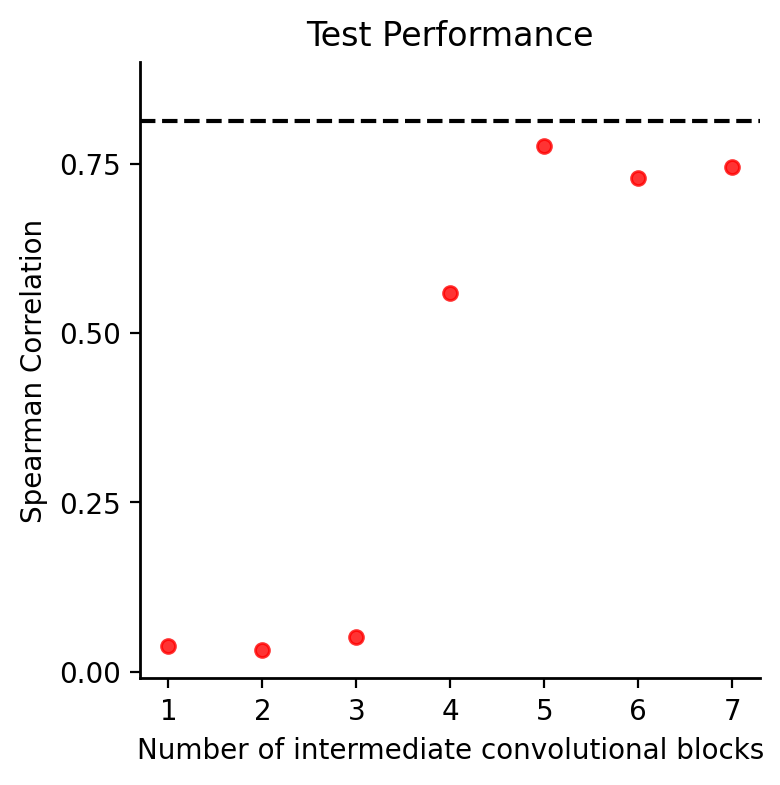

In [8]:
fig, ax = plt.subplots(figsize=(4, 4))
plt.scatter(df_16['conv_layers'], df_16['spearman'], s=25, color='red', alpha=0.8, label='16')

plt.grid(False)


ax.spines['top'].set_visible(False)     
ax.spines['right'].set_visible(False)   
ax.spines['left'].set_edgecolor('black')  
ax.spines['left'].set_linewidth(1)      
ax.spines['bottom'].set_edgecolor('black')
ax.spines['bottom'].set_linewidth(1)  
ax.yaxis.set_tick_params(left=True)   
ax.xaxis.set_tick_params(bottom=True) 
plt.axhline(y=rep_spearman, linestyle='dashed', color='black')
ax.set_yticks([0, 0.25, 0.5, 0.75])
ax.set_xticks([1, 2, 3, 4, 5, 6, 7])
plt.ylim([-0.01, 0.9])

plt.xlabel('Number of intermediate convolutional blocks')
plt.ylabel('Spearman Correlation')
plt.title('Test Performance')
plt.show()
# plt.savefig("fig1e.pdf", format="pdf")